# Heart Disease Prediction

Dataset: [UCI Heart Disease Data (Cleveland)- Kaggle )

**Goal:** predict whether a patient has heart disease (`target`: 1 = No, 0 = Yes) based on 13 clinical attributes (age, blood pressure, cholesterol, ECG results, etc.).

**Notebook structure:**
1. Import libraries & load data
2. Data Loading and Cleaning
3. Exploratory Data Analysis (EDA)
4. Train / Validation / Test Split
5. Modeling (Dummy Clasifier, Logistic Regression, Random Forest, KNN, Gradient Boosting)
6. Model evaluation & comparison
7. Feature importance
8. Conclusion


## 1. Import Libraries & Load Data


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, precision_recall_curve,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_curve)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# 2. Data Loading and Cleaning

### 2.1. Inspect Data

In [2]:
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [4]:
df.shape

(303, 14)

In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


### 2.2. Data Cleaning

In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Number of duplicate rows: 1


In [7]:
df = df.drop_duplicates()
df.shape

(302, 14)

In [8]:
categorical_columns = ['sex', 'fbs', 'exang', 'cp', 'restecg', 'slope', 'ca', 'thal']
for col in categorical_columns:
    print(df[col].value_counts().sort_index())

sex
0     96
1    206
Name: count, dtype: int64
fbs
0    257
1     45
Name: count, dtype: int64
exang
0    203
1     99
Name: count, dtype: int64
cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64
restecg
0    147
1    151
2      4
Name: count, dtype: int64
slope
0     21
1    140
2    141
Name: count, dtype: int64
ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64
thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64


In [9]:
numerical_columns = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

In [10]:
#there are invalid value 4 for ca and 0 for thal, so we delete them
df = df[df['ca'] != 4]
df = df[df['thal'] != 0]

## 3. Exploratory Data Analysis (EDA)

In [11]:
#make sure the target, bcs exang, ca and oldpeak of 1 is lower then 0 and the thalach of 1 is higher thn 0, that means 1 is no heart disease
df.groupby('target')[['exang', 'ca', 'oldpeak', 'thalach']].mean().round(2)

,exang,ca,oldpeak,thalach
target,,,,
0,0.54,1.15,1.6,138.95
1,0.14,0.28,0.6,158.58


In [12]:
df['target'] = 1 - df['target']

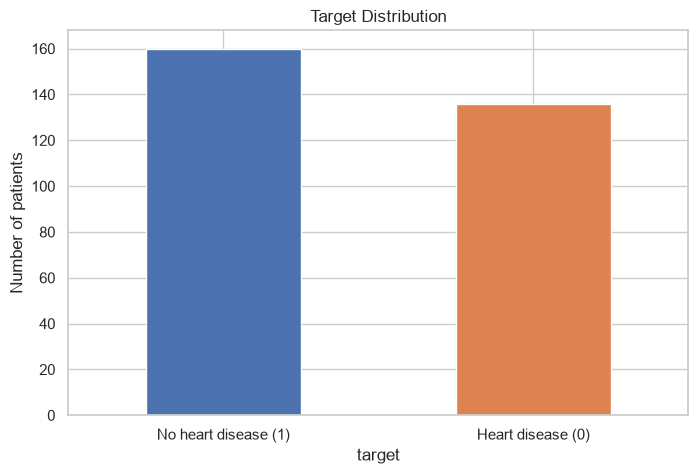

In [13]:
# Target distribution (is the dataset balanced?)
ax = df["target"].value_counts().sort_index().plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_xticklabels(["No heart disease (1)", "Heart disease (0)"], rotation=0)
ax.set_title("Target Distribution")
ax.set_ylabel("Number of patients")
plt.show()


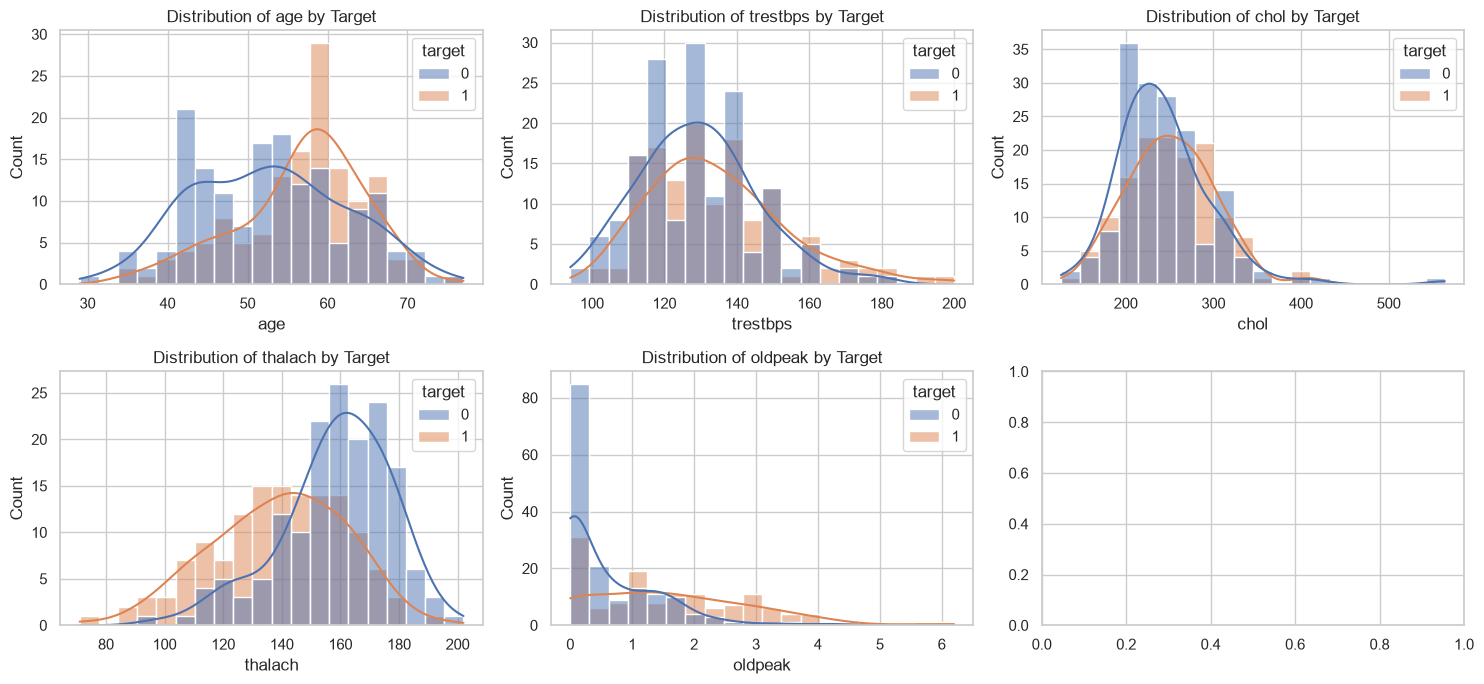

          age  trestbps    chol  thalach  oldpeak
target                                           
0       52.64    129.18  243.49   158.58      0.6
1       56.74    134.46  251.46   138.95      1.6


In [14]:
# numerical columns distribution by target
fig, axes = plt.subplots(2,3, figsize=(15,7))
for ax, c in zip(axes.flatten(), numerical_columns):
    sns.histplot(data=df, x=c, hue="target", kde=True, bins=20, palette=["#4C72B0", "#DD8452"], ax=ax)
    ax.set_title(f'Distribution of {c} by Target')
    ax.set_xlabel(c)
plt.tight_layout()
plt.show()
print(df.groupby('target')[numerical_columns].mean().round(2))

In [15]:
df[numerical_columns].skew()

age        -0.214413
trestbps    0.710759
chol        1.129905
thalach    -0.531671
oldpeak     1.243552
dtype: float64

- **thalach**: Strongest separator. Patients with heart disease have a much lower mean max heart rate (139 vs 159 bpm).
- **oldpeak**: Strong separator. Healthy patients cluster at 0, while the disease group has higher, right skewed values (mean 1.6 vs 0.6).
- **age**: Moderate. The disease is about 4 years older on average (56.7 vs 52.6).
- **trestbps & chol**: Weak. Means differ slightly and the distributions largely overlap.

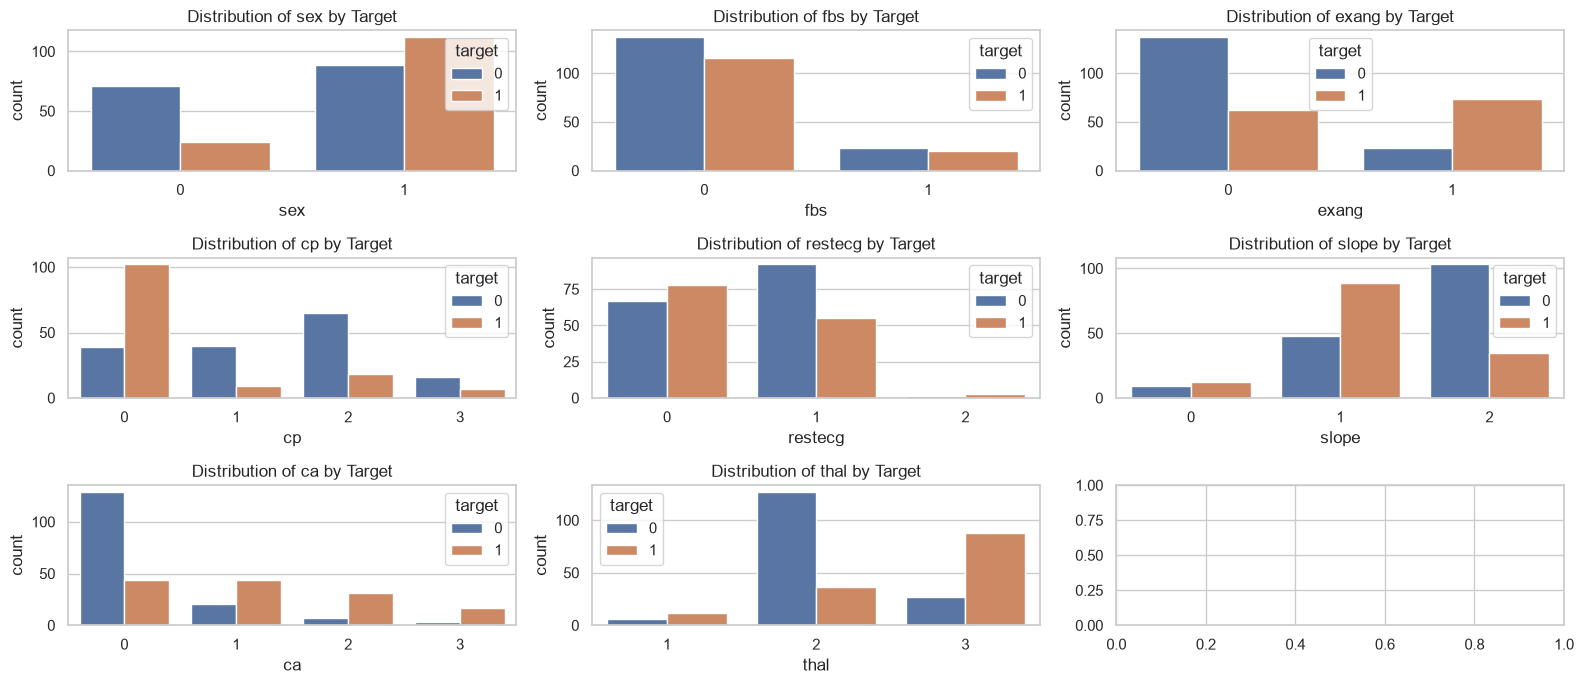

In [16]:
# categorical columns distribution by target
fig, axes = plt.subplots(3,3, figsize=(16,7))
for ax, c in zip(axes.flatten(), categorical_columns):
    sns.countplot(data=df, x=c, hue="target", palette=["#4C72B0", "#DD8452"], ax=ax)
    ax.set_title(f'Distribution of {c} by Target')
    ax.set_xlabel(c)
plt.tight_layout()
plt.show()

- **cp**: Strongest. Chest pain type o (asymptomatic) is mostly disease; types 1-3 are mostly healthy.
- **exang**: Strong. Exercise-induced angina (1) is mostly disease; no angina (0) is mostly healthy.
- **ca**: Strong. 0 vessels is mostly healthy; 1 or more is mostly disease.
- **thal**: Strong. Normal (2) is mostly healthy; reversible detect (3) is mostly disease.
- **slope**: Moderate to strong. Flat (1) leans diasese; upsloping (2) leans healthy. 
- **sex**: Moderate. Males have a higher disease rate;  females are mostly healthy.
- **restecg**: Weak to moderate. Category 0 leans disease and 1 leans healthy; category 2 is too rare to judge.
- **fbs**: Weak. The disease/healthy ratio is similar to both category.

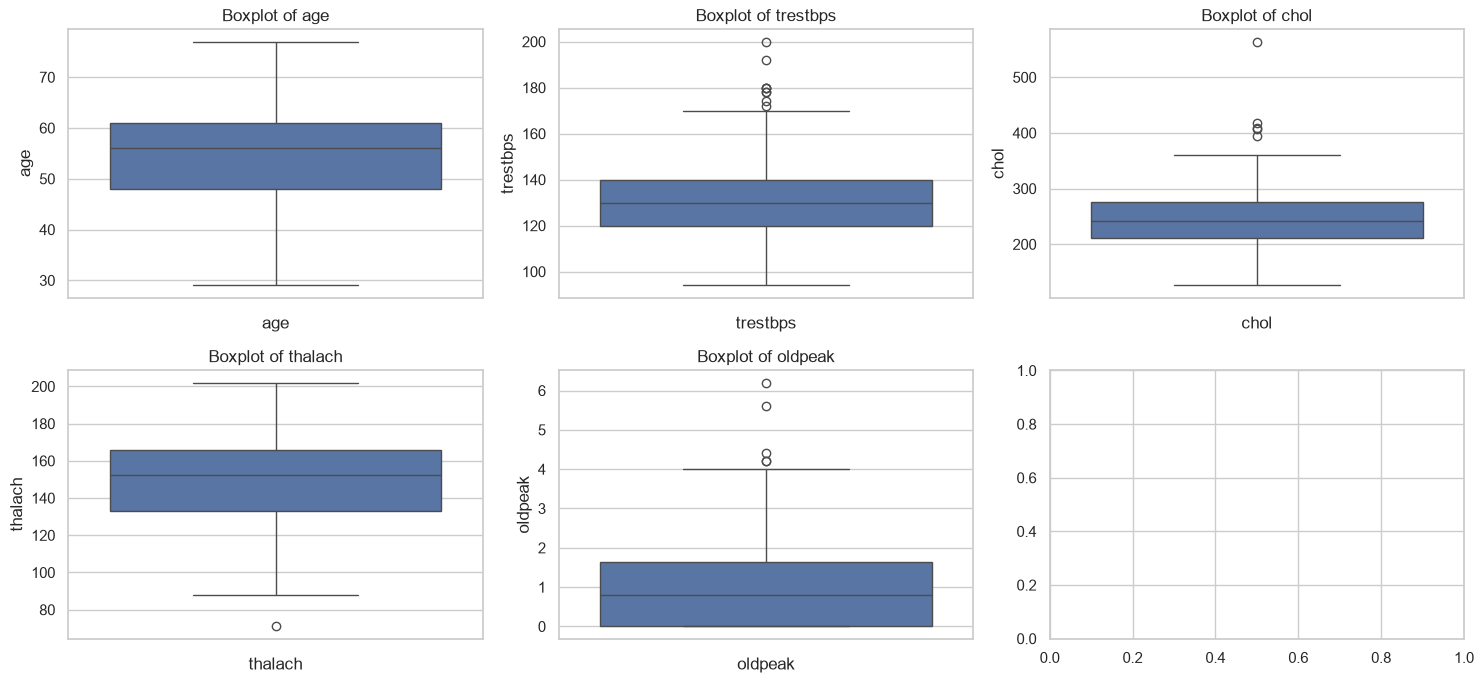

In [17]:
#outlier checking (univariate analysis)
fig, axes = plt.subplots(2,3, figsize=(15,7))
for ax, c in zip(axes.flatten(), numerical_columns):
    sns.boxplot(data=df, y=c, ax=ax)
    ax.set_title(f'Boxplot of {c}')
    ax.set_xlabel(c)
plt.tight_layout()
plt.show()

In [18]:
for col in numerical_columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f'{col}: Upper bound {upper_bound:.1f} - Lower bound {lower_bound:.1f} | Number of outliers: {len(outliers)} outliers')


age: Upper bound 80.5 - Lower bound 28.5 | Number of outliers: 0 outliers
trestbps: Upper bound 170.0 - Lower bound 90.0 | Number of outliers: 9 outliers
chol: Upper bound 371.6 - Lower bound 114.6 | Number of outliers: 5 outliers
thalach: Upper bound 215.5 - Lower bound 83.5 | Number of outliers: 1 outliers
oldpeak: Upper bound 4.1 - Lower bound -2.5 | Number of outliers: 5 outliers


##### Outliers were detected in several numerical columns (e.g. `chol`, `trestbps`, `thalach` and `oldpeak`) but the value are still medically plausible and the dataset is small, so the outliers retained.

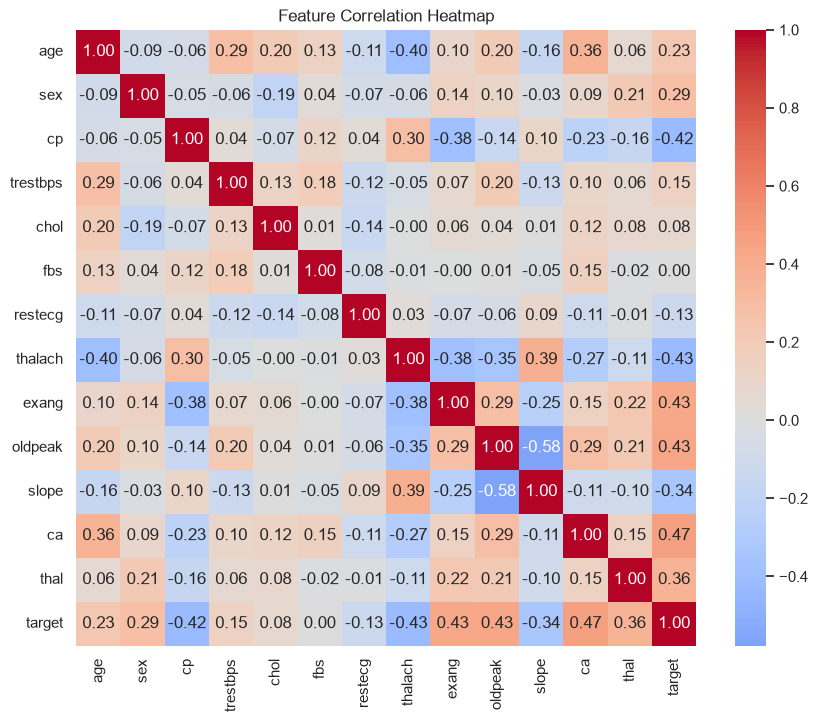

In [19]:
# Correlation heatmap of numerical features
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()


# 4. Train / Validation / Test Split

Steps:
- Split features (`X`) and target (`y`)
- Train/test split (60/20/20, stratified since this is classification)
- Standardize numerical features so models like Logistic Regression & KNN aren't biased by scale


In [20]:
X = df.drop(columns=["target"])
y = df["target"]

# 60% train, 20% validation, 20% test (stratified to keep the churn rate in every part)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

for name, part in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]:
    print(f'{name:<11} rows: {len(part):>5}   churn rate: {part.mean():.3f}')
print("Train:", X_train.shape, " Test:", X_test.shape)


Train       rows:   177   churn rate: 0.458
Validation  rows:    59   churn rate: 0.458
Test        rows:    60   churn rate: 0.467
Train: (177, 13)  Test: (60, 13)


### 4.1. Preprocessing

In [21]:
#log1p for columns with skew>1
log_col = ['chol', 'oldpeak']
plain_col= ['age', 'trestbps','thalach']
## Logistic Regression: scale numeric features and one-hot encode categorical features
preprocessor_scaled_log = ColumnTransformer([
    ('num', StandardScaler(), plain_col), ('log', Pipeline([('log', FunctionTransformer(np.log1p)), ('sc', StandardScaler())]), log_col),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)])
# Tree-based models: no scaling needed, only one-hot encoding
preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', numerical_columns),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
])


# 5. Modeling

### 5.1. Baseline: Dummy Classifier

The baseline always predicts the majority class (stayed). Any useful model must beat it on the churn class.

In [22]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

pred = dummy.predict(X_valid)
print(accuracy_score(y_valid, pred))

0.5423728813559322


### 5.2. Baseline : Logistic Regression

### 5.3. Cross-Validation on the Training Set

In [23]:
base = Pipeline([
    ('pre', preprocessor_scaled_log),
    ('clf', LogisticRegression(max_iter = 1000))
])

base.fit(X_train, y_train)

pred = base.predict(X_valid)
proba = base.predict_proba(X_valid)[:, 1]

print(classification_report(y_valid, pred))
print('ROC-AUC:', round(roc_auc_score(y_valid, proba), 3))

              precision    recall  f1-score   support

           0       0.91      0.91      0.91        32
           1       0.89      0.89      0.89        27

    accuracy                           0.90        59
   macro avg       0.90      0.90      0.90        59
weighted avg       0.90      0.90      0.90        59

ROC-AUC: 0.961


In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    'Logistic Regression': (preprocessor_scaled_log, LogisticRegression(max_iter=1000, random_state=42)),
    "Random Forest": (preprocessor_tree, RandomForestClassifier(n_estimators=200, random_state=42, max_depth=4, min_samples_leaf=5)),
    "KNN": (preprocessor_scaled_log, KNeighborsClassifier()),
    'SVM' : (preprocessor_scaled_log, SVC(probability=True)),
    'GrandBoost': (preprocessor_tree, GradientBoostingClassifier(random_state=42))
}

results = []

for name, (pre, clf) in models.items():
    pipe = Pipeline([('pre', pre), ('clf', clf)])
    r= cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy','precision','recall','f1','roc_auc'])
    results.append({
        "Model": name,
        "Accuracy": r['test_accuracy'].mean(),
        "Precision": r['test_precision'].mean(),
        "Recall": r['test_recall'].mean(),
        "F1-Score": r['test_f1'].mean(),
        "ROC-AUC": r['test_roc_auc'].mean(),
    })

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).set_index('Model')
results_df


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `Cal

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.830794,0.832262,0.790441,0.810000,0.904789
SVM,0.825556,0.851786,0.753676,0.797101,0.887775
Random Forest,0.808571,0.813277,0.754412,0.781310,0.896190
KNN,0.796984,0.824199,0.716912,0.763820,0.856389
GrandBoost,0.774286,0.775000,0.740441,0.750833,0.849414


# 6. Evaluation

### 6.1. Model Comparison

In [25]:
def evaluate(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'Accuracy': accuracy_score(y, pred),
        'Precision ': precision_score(y, pred),
        'Recall ': recall_score(y, pred),
        'F1 ': f1_score(y, pred),
        'ROC-AUC': roc_auc_score(y, proba),
    }

fitted = {}
rows = []
for name, (pre, clf) in models.items():
    pipe = Pipeline([('pre', pre), ('clf', clf)])
    pipe.fit(X_train, y_train)
    fitted[name]= pipe
    for split, (X_, y_) in {'Train' : (X_train, y_train), 'Validation': (X_valid, y_valid)}.items():
        rows.append({'Model' : name, 'Set' : split, **evaluate(pipe, X_, y_)})

compare = pd.DataFrame(rows).set_index(['Model', 'Set']).round(3)
compare

C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy  Precision   Recall     F1   ROC-AUC
Model               Set                                                      
Logistic Regression Train          0.864       0.890    0.802  0.844    0.936
                    Validation     0.898       0.889    0.889  0.889    0.961
Random Forest       Train          0.881       0.905    0.827  0.865    0.954
                    Validation     0.814       0.833    0.741  0.784    0.927
KNN                 Train          0.842       0.853    0.790  0.821    0.931
                    Validation     0.814       0.767    0.852  0.807    0.890
SVM                 Train          0.910       0.945    0.852  0.896    0.967
                    Validation     0.847       0.875    0.778  0.824    0.942
GrandBoost          Train          1.000       1.000    1.000  1.000    1.000
                    Validation     0.847       0.875    0.778  0.824    0.919

### 6.2. Confusion Matrices

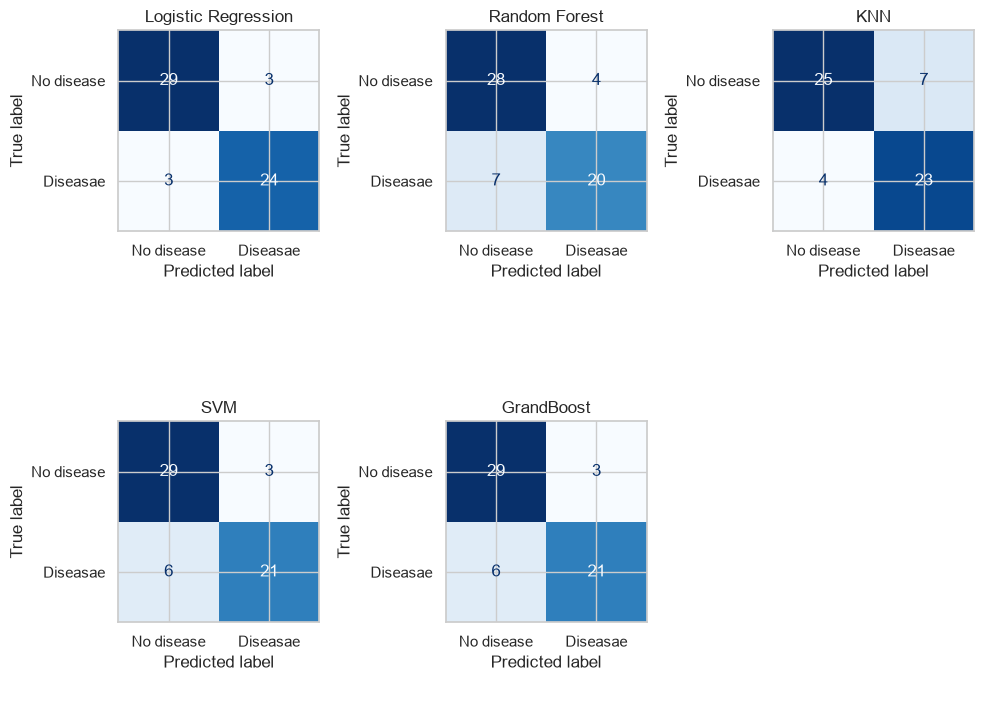

In [28]:
labels = ['No disease','Diseasae']
fig, axes = plt.subplots(2, 3, figsize=(10, 8))
for ax, (name, pipe) in zip(axes.flatten(), fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_valid, y_valid,
                                          display_labels=labels, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

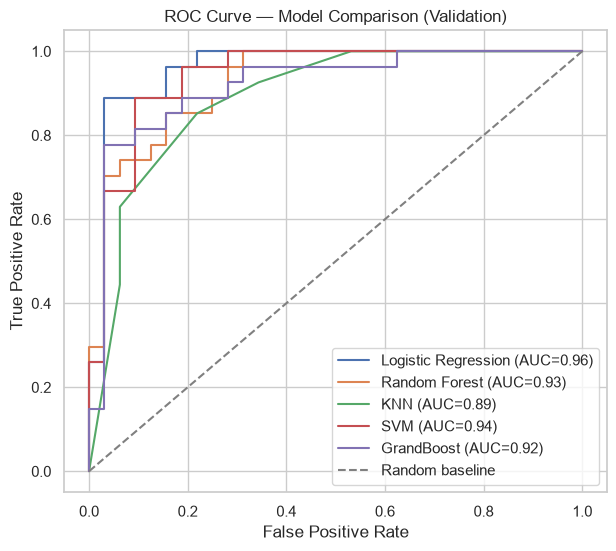

In [39]:
# ROC curve for each model
plt.figure(figsize=(7, 6))
for name, model in fitted.items():
    y_proba = model.predict_proba(X_valid)[:,1]
    fpr, tpr, _ = roc_curve(y_valid, y_proba)
    auc = roc_auc_score(y_valid, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Model Comparison (Validation)")
plt.legend()
plt.show()


In [38]:
best_model_name = results_df.index[0]
print(f"Best model by F1-Score: {best_model_name}\n")
print(classification_report(y_valid, fitted[best_model_name].predict(X_valid)))


Best model by F1-Score: Logistic Regression

              precision    recall  f1-score   support

           0       0.91      0.91      0.91        32
           1       0.89      0.89      0.89        27

    accuracy                           0.90        59
   macro avg       0.90      0.90      0.90        59
weighted avg       0.90      0.90      0.90        59



## 7. Feature Importance (Logistic Regression)

28 28
0 NaN


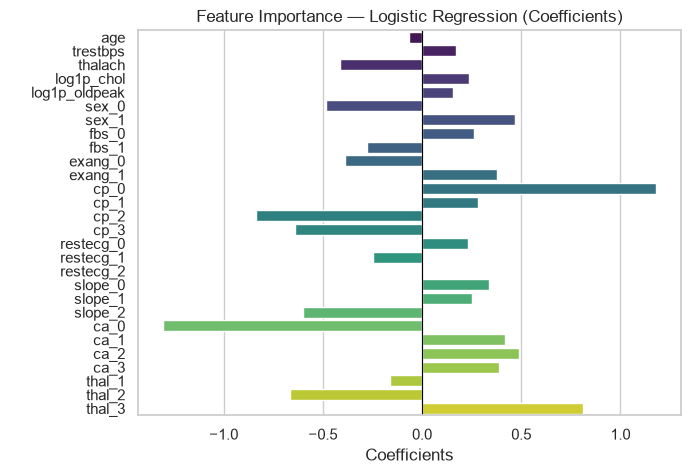

,feature,coef,abs
0,age,-0.068166,0.068166
1,trestbps,0.168627,0.168627
2,thalach,-0.413131,0.413131
3,log1p_chol,0.237943,0.237943
4,log1p_oldpeak,0.155437,0.155437


In [46]:
lr_pipe = fitted["Logistic Regression"]
pre = lr_pipe.named_steps['pre']

cat_names = pre.named_transformers_['cat'].get_feature_names_out(categorical_columns)
names = list(plain_col) + ['log1p_' + c for c in log_col] + list(cat_names)
coefs = lr_pipe.named_steps['clf'].coef_.ravel()

print(len(names), len(coefs))

coef_df = pd.DataFrame({'feature': names, 'coef': coefs})
coef_df['abs'] = coef_df['coef'].abs()
coef=coef_df.sort_values('abs', ascending=False)

print(coef_df['coef'].isna().sum(), 'NaN')

plt.figure(figsize=(7, 5))
sns.barplot(data=coef_df, x='coef', y='feature', hue='feature', palette="viridis", legend=False)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Feature Importance — Logistic Regression (Coefficients)")
plt.xlabel("Coefficients")
plt.ylabel(' ')
plt.show()

coef_df.head()

## 8. Conclusion

**Best model:** Logistic Regression. It had the best 5-fold CV F1 (0.81) and ROC-AUC (0.91), showed no overfitting(train F1 0.84 vs validation 0.89) and is easy to interpret. Random Forest and Gradient Boosting overfi the small training set and KNN scored lowest. on the held-out test set it reached accuracy , recall, F1, and ROC-AUC.

**Most influential features:** Both EDA and the model coefficients point to `thalach` (lower max heart rate → higher risk), `oldpeak` → 0.155, `chol` → 0.238, and `thal` → -0.413.

**Key EDA insights:**
- The target labels were reversed relative to the documentation. this was verified with `exang`, `ca`, `oldpeak` and `thalach`, then corrected.
- Classes are balanced (46% healthy / 54% disease before the flip, 54% / 46% after)
- Outliers (<2%, e.g. `chol`) are medically plausible, so they were kept.
- `chol` and `oldpeak` were right-skew, so `log1p` was applied for the scale-sensitive models.

**Limitations and next steps:**
- Small dataset: the validation and test sets have about 60 rows each, so diffeneces of 1-2 points between models are not reliable.
- No hyperparameter tuning was done; next step is `GridSearchCV`on the top models.
- Result shows associations, not causation, and the model is not for clinical use.
---